1 — Imports

In [1]:
import os, json, re, random
from pathlib import Path
from typing import List, Dict, Any

import numpy as np
from PIL import Image

import torch
from torch.utils.data import Dataset

from transformers import (
    AutoImageProcessor,
    AutoTokenizer,
    VisionEncoderDecoderModel,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
    set_seed,
)

print("torch:", torch.__version__)
import transformers
print("transformers:", transformers.__version__)
print("cuda:", torch.cuda.is_available())

/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch: 2.5.1+cu121
transformers: 4.57.1
cuda: True


2 — Config (edit only DATA_ROOT if needed)

In [2]:
DATA_ROOT = Path("/home/psivakumar/thesis/data/iu_xray")
ANN_PATH = DATA_ROOT / "annotation_full.json"
SPLIT_PATH = DATA_ROOT / "split_uids.json"

RUN_DIR = DATA_ROOT / "runs" / "vit_gpt_baseline"
RUN_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
set_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)

ENCODER_NAME = "google/vit-base-patch16-224-in21k"
DECODER_NAME = "gpt2"

MAX_TARGET_LEN = 256
NUM_BEAMS = 3

EPOCHS = 5
LR = 5e-5
BATCH_SIZE = 8

DEVICE: cuda


3 — Load annotation + create split file if missing

In [3]:
assert ANN_PATH.exists(), f"Missing: {ANN_PATH}"

with open(ANN_PATH, "r", encoding="utf-8") as f:
    records = json.load(f)

uids = sorted(list({r["uid"] for r in records}))
print("Total uids:", len(uids))

if not SPLIT_PATH.exists():
    print("split_uids.json not found -> creating 80/10/10 split")
    rng = random.Random(SEED)
    rng.shuffle(uids)

    n = len(uids)
    n_train = int(0.80 * n)
    n_val = int(0.10 * n)

    splits = {
        "train": uids[:n_train],
        "val": uids[n_train:n_train+n_val],
        "test": uids[n_train+n_val:],
    }
    with open(SPLIT_PATH, "w", encoding="utf-8") as f:
        json.dump(splits, f, indent=2)
    print("Saved:", SPLIT_PATH)
else:
    with open(SPLIT_PATH, "r", encoding="utf-8") as f:
        splits = json.load(f)
    print("Loaded:", SPLIT_PATH)

uid2rec = {r["uid"]: r for r in records}

train_recs = [uid2rec[u] for u in splits["train"] if u in uid2rec]
val_recs   = [uid2rec[u] for u in splits["val"]   if u in uid2rec]
test_recs  = [uid2rec[u] for u in splits["test"]  if u in uid2rec]

print("Splits:", len(train_recs), len(val_recs), len(test_recs))
print("Sample keys:", train_recs[0].keys())

Total uids: 3376
Loaded: /home/psivakumar/thesis/data/iu_xray/split_uids.json
Splits: 2700 337 339
Sample keys: dict_keys(['uid', 'frontal', 'lateral', 'report'])


4 — Text cleaning

In [4]:
_ws = re.compile(r"\s+")

def clean_report(t: str) -> str:
    if t is None:
        return ""
    return _ws.sub(" ", t.strip())

5 — 2-view composite (frontal + lateral)

In [5]:
def make_two_view_composite(frontal_path: str, lateral_path: str, out_size=224) -> Image.Image:
    f = Image.open(frontal_path).convert("L").resize((out_size, out_size), Image.BICUBIC)
    l = Image.open(lateral_path).convert("L").resize((out_size, out_size), Image.BICUBIC)

    canvas = Image.new("L", (out_size * 2, out_size))
    canvas.paste(f, (0, 0))
    canvas.paste(l, (out_size, 0))

    canvas = canvas.resize((out_size, out_size), Image.BICUBIC)
    return canvas.convert("RGB")

6 — Processor + Tokenizer (fix GPT2 padding)

In [6]:
image_processor = AutoImageProcessor.from_pretrained(ENCODER_NAME)
tokenizer = AutoTokenizer.from_pretrained(DECODER_NAME)

if tokenizer.pad_token is None:
    tokenizer.add_special_tokens({"pad_token": "<|pad|>"})

print("pad:", tokenizer.pad_token_id, "eos:", tokenizer.eos_token_id)

Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.


pad: 50257 eos: 50256


7 — Dataset

In [7]:
class IUXrayDataset(Dataset):
    def __init__(self, recs: List[Dict[str, Any]]):
        self.recs = recs

    def __len__(self):
        return len(self.recs)

    def __getitem__(self, idx: int):
        r = self.recs[idx]

        # IMPORTANT: your json must contain these keys
        frontal = r["frontal"]
        lateral = r["lateral"]
        report  = clean_report(r["report"])

        # image -> pixel_values
        img = make_two_view_composite(frontal, lateral, out_size=224)
        pixel_values = image_processor(images=img, return_tensors="pt").pixel_values.squeeze(0)

        # text -> labels
        tok = tokenizer(
            report,
            max_length=MAX_TARGET_LEN,
            truncation=True,
            padding="max_length",
            return_tensors="pt",
        )
        labels = tok.input_ids.squeeze(0)
        labels[labels == tokenizer.pad_token_id] = -100

        return {"pixel_values": pixel_values, "labels": labels}

train_ds = IUXrayDataset(train_recs)
val_ds   = IUXrayDataset(val_recs)
test_ds  = IUXrayDataset(test_recs)

x = train_ds[0]
print("pixel_values:", x["pixel_values"].shape, "labels:", x["labels"].shape)

pixel_values: torch.Size([3, 224, 224]) labels: torch.Size([256])


8 — Model (ViT encoder + GPT2 decoder)

In [8]:
model = VisionEncoderDecoderModel.from_encoder_decoder_pretrained(
    ENCODER_NAME,
    DECODER_NAME,
)

# resize because we added pad token
model.decoder.resize_token_embeddings(len(tokenizer))

model.config.pad_token_id = tokenizer.pad_token_id
model.config.eos_token_id = tokenizer.eos_token_id
model.config.decoder_start_token_id = tokenizer.bos_token_id if tokenizer.bos_token_id is not None else tokenizer.eos_token_id

model.config.max_length = MAX_TARGET_LEN
model.config.num_beams = NUM_BEAMS

model.to(DEVICE)
print("Model ready on", DEVICE)

Some weights of GPT2LMHeadModel were not initialized from the model checkpoint at gpt2 and are newly initialized: ['transformer.h.0.crossattention.c_attn.bias', 'transformer.h.0.crossattention.c_attn.weight', 'transformer.h.0.crossattention.c_proj.bias', 'transformer.h.0.crossattention.c_proj.weight', 'transformer.h.0.crossattention.q_attn.bias', 'transformer.h.0.crossattention.q_attn.weight', 'transformer.h.0.ln_cross_attn.bias', 'transformer.h.0.ln_cross_attn.weight', 'transformer.h.1.crossattention.c_attn.bias', 'transformer.h.1.crossattention.c_attn.weight', 'transformer.h.1.crossattention.c_proj.bias', 'transformer.h.1.crossattention.c_proj.weight', 'transformer.h.1.crossattention.q_attn.bias', 'transformer.h.1.crossattention.q_attn.weight', 'transformer.h.1.ln_cross_attn.bias', 'transformer.h.1.ln_cross_attn.weight', 'transformer.h.10.crossattention.c_attn.bias', 'transformer.h.10.crossattention.c_attn.weight', 'transformer.h.10.crossattention.c_proj.bias', 'transformer.h.10.cros

Model ready on cuda


DataLoaders

In [11]:
from torch.utils.data import DataLoader

NUM_WORKERS = 4  # change to 0 if your node has dataloader issues

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

print("train batches:", len(train_loader))
print("val batches:", len(val_loader))

train batches: 338
val batches: 43


Optimizer + AMP scaler (safe)

In [12]:
from torch.optim import AdamW

optimizer = AdamW(model.parameters(), lr=LR)

use_amp = torch.cuda.is_available()
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

print("AMP enabled:", use_amp)

AMP enabled: True


/tmp/ipykernel_324397/2943657483.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


(Important) Small helper: move batch to device

In [13]:
def to_device(batch, device):
    return {k: v.to(device, non_blocking=True) for k, v in batch.items()}

One epoch train + one epoch validate (clean)

In [15]:
def train_one_epoch(epoch: int, log_every: int = 50):
    model.train()
    total_loss = 0.0

    for step, batch in enumerate(train_loader, start=1):
        batch = to_device(batch, DEVICE)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=use_amp):
            out = model(pixel_values=batch["pixel_values"], labels=batch["labels"])
            loss = out.loss

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += float(loss.item())

        if step % log_every == 0:
            avg = total_loss / step
            print(f"Epoch {epoch} | step {step}/{len(train_loader)} | loss {loss.item():.4f} | avg {avg:.4f}")

    return total_loss / max(1, len(train_loader))


@torch.no_grad()
def validate_one_epoch(epoch: int):
    model.eval()
    total_loss = 0.0

    for batch in val_loader:
        batch = to_device(batch, DEVICE)

        with torch.cuda.amp.autocast(enabled=use_amp):
            out = model(pixel_values=batch["pixel_values"], labels=batch["labels"])
            loss = out.loss

        total_loss += float(loss.item())

    return total_loss / max(1, len(val_loader))

Training loop + save best checkpoint

In [16]:
best_val = float("inf")
history = {"train_loss": [], "val_loss": []}

for epoch in range(1, EPOCHS + 1):
    tr_loss = train_one_epoch(epoch, log_every=50)
    va_loss = validate_one_epoch(epoch)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)

    print(f"\n✅ Epoch {epoch}/{EPOCHS} done")
    print(f"Train Loss: {tr_loss:.4f} | Val Loss: {va_loss:.4f}\n")

    if va_loss < best_val:
        best_val = va_loss
        model.save_pretrained(str(RUN_DIR))
        tokenizer.save_pretrained(str(RUN_DIR))
        image_processor.save_pretrained(str(RUN_DIR))
        print("💾 Saved BEST model to:", RUN_DIR)

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The 

Epoch 1 | step 50/338 | loss 3.9824 | avg 6.1333
Epoch 1 | step 100/338 | loss 3.8266 | avg 4.9754
Epoch 1 | step 150/338 | loss 3.6336 | avg 4.4433
Epoch 1 | step 200/338 | loss 3.5355 | avg 4.1459
Epoch 1 | step 250/338 | loss 3.2355 | avg 3.9072
Epoch 1 | step 300/338 | loss 2.4420 | avg 3.7222


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The 


✅ Epoch 1/5 done
Train Loss: 3.5949 | Val Loss: 2.5692



/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/transformers/modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 256, 'num_beams': 3}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


💾 Saved BEST model to: /home/psivakumar/thesis/data/iu_xray/runs/vit_gpt_baseline


... (12 outputs left out)

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The 

Epoch 5 | step 50/338 | loss 2.3226 | avg 1.8238
Epoch 5 | step 100/338 | loss 1.9232 | avg 1.8174
Epoch 5 | step 150/338 | loss 1.3632 | avg 1.8353
Epoch 5 | step 200/338 | loss 2.2676 | avg 1.8343
Epoch 5 | step 250/338 | loss 2.0407 | avg 1.8287
Epoch 5 | step 300/338 | loss 1.9534 | avg 1.8452


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The 


✅ Epoch 5/5 done
Train Loss: 1.8380 | Val Loss: 1.9182

💾 Saved BEST model to: /home/psivakumar/thesis/data/iu_xray/runs/vit_gpt_baseline


In [21]:
from transformers import GenerationConfig

model.generation_config = GenerationConfig(
    max_length=MAX_TARGET_LEN,
    num_beams=NUM_BEAMS,
    no_repeat_ngram_size=3,
    early_stopping=True,
    pad_token_id=tokenizer.pad_token_id,
    eos_token_id=tokenizer.eos_token_id,
)

In [33]:
from transformers import GenerationConfig

model.generation_config = GenerationConfig(
    max_new_tokens=160,          # keep shorter; helps stop loops
    num_beams=1,                 # IMPORTANT: disable beam search (it can amplify repetition here)
    do_sample=True,              # sampling is more stable for GPT2 here
    top_p=0.9,
    temperature=0.8,

    repetition_penalty=1.2,
    no_repeat_ngram_size=4,

    pad_token_id=tokenizer.pad_token_id,
    eos_token_id=tokenizer.eos_token_id,
    decoder_start_token_id=model.config.decoder_start_token_id,
)
print("✅ generation_config set")

✅ generation_config set


Inference function (frontal+lateral → report)

In [34]:
@torch.no_grad()
def generate_report(frontal_path: str, lateral_path: str) -> str:
    model.eval()
    img = make_two_view_composite(frontal_path, lateral_path, out_size=224)
    pixel_values = image_processor(images=img, return_tensors="pt").pixel_values.to(DEVICE)

    out_ids = model.generate(pixel_values)
    return tokenizer.decode(out_ids[0], skip_special_tokens=True).strip()

Test DataLoader + Test Loss

In [24]:
from torch.amp import autocast
import numpy as np

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

@torch.no_grad()
def evaluate_loss(loader):
    model.eval()
    total = 0.0

    for batch in loader:
        batch = to_device(batch, DEVICE)

        with autocast(device_type="cuda", enabled=use_amp):
            out = model(pixel_values=batch["pixel_values"], labels=batch["labels"])
            total += float(out.loss.item())

    return total / max(1, len(loader))


test_loss = evaluate_loss(test_loader)
print("TEST loss:", test_loss)
print("TEST perplexity (approx):", float(np.exp(test_loss)))

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The 

TEST loss: 1.8608918009802353
TEST perplexity (approx): 6.429468021365981


In [31]:
# Ensure special tokens are set correctly for VisionEncoderDecoder generation
model.config.pad_token_id = tokenizer.pad_token_id
model.config.eos_token_id = tokenizer.eos_token_id

# GPT2 usually has no BOS, so use EOS as start token (common workaround)
start_id = tokenizer.bos_token_id
if start_id is None:
    start_id = tokenizer.eos_token_id

model.config.decoder_start_token_id = start_id

print("pad:", model.config.pad_token_id,
      "eos:", model.config.eos_token_id,
      "decoder_start:", model.config.decoder_start_token_id)

pad: 50257 eos: 50256 decoder_start: 50256


Quick test on 3 samples

In [35]:
import random

for i in range(3):
    r = random.choice(test_recs)
    pred = generate_report(r["frontal"], r["lateral"])

    print("\n" + "="*80)
    print(f"Sample {i+1} | UID: {r['uid']}")
    print("\nGT:\n", clean_report(r["report"])[:600])
    print("\nPRED:\n", pred[:600])


Sample 1 | UID: 1061

GT:
 The heart, pulmonary and mediastinum are within normal limits. There is no pleural effusion or pneumothorax. There is no focal air space opacity to suggest a pneumonia. There is slight wedge deformity of the mid to lower thoracic vertebral body unchanged from the comparison study. IMPRESSION: No acute cardiopulmonary disease.

PRED:
 size cardomedast silhouette pulmonarycul are.monaryity within limits normal There diffusestitialac in left lobe otherwise lungs clear Nouralusions pneumor orothaces Heart is enlarged Deative throughout thoricrosoticifications the tissues IMION 1 Mildiin chronic inter ed, acute disease noted with consolidation no of findings 2 Chronicse lung without cardiacement..imposedchotomy 5 Sequae intact mildile ostetes unchanged prior infection viral from films Please to for further as and document possible differences If were this be regarding patient/ologist please clinical notification by staff physic

Sample 2 | UID: 2877

GT:
 The car

Loss curves

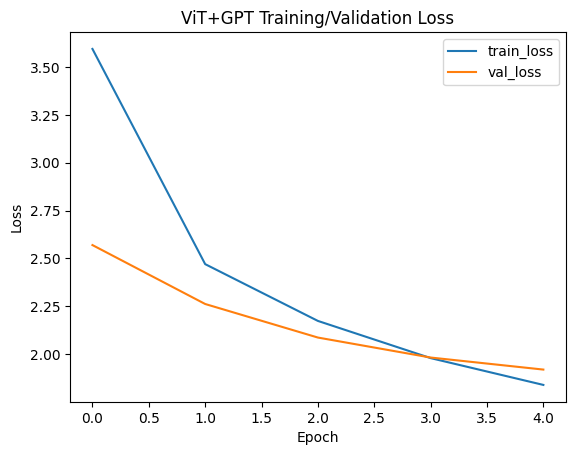

In [36]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(history["train_loss"], label="train_loss")
plt.plot(history["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ViT+GPT Training/Validation Loss")
plt.legend()
plt.show()

Test Loss & Perplexity

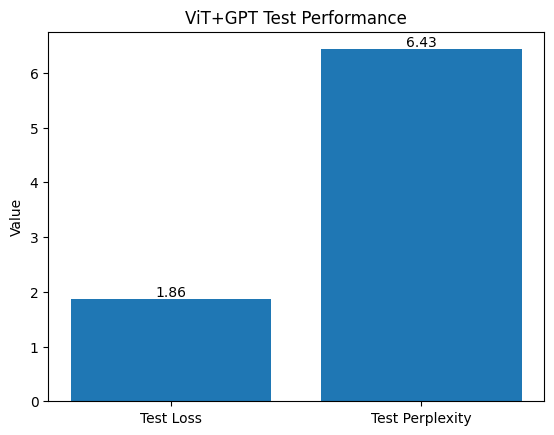

In [37]:
import matplotlib.pyplot as plt
import numpy as np

# Your already computed values
test_loss = 1.8608918009802353
test_ppl  = 6.429468021365981

labels = ["Test Loss", "Test Perplexity"]
values = [test_loss, test_ppl]

x = np.arange(len(labels))

plt.figure()
plt.bar(x, values)
plt.xticks(x, labels)
plt.ylabel("Value")
plt.title("ViT+GPT Test Performance")

# annotate bars
for i, v in enumerate(values):
    plt.text(i, v, f"{v:.2f}", ha="center", va="bottom")

plt.show()

In [1]:
import re

def is_normal(report: str) -> int:
    t = (report or "").lower()

    normal_patterns = [
        r"no acute",
        r"no evidence of",
        r"normal",
        r"negative for acute",
        r"no pneumothorax",
        r"no pleural effusion",
        r"no focal consolidation",
    ]

    # If any strong "normal" signal, classify as normal
    for p in normal_patterns:
        if re.search(p, t):
            return 1
    return 0  # abnormal

In [2]:
import random
import numpy as np

N = 200  # increase to 500 if you want stronger stats

y_true = []
y_pred = []

samples = random.sample(test_recs, k=min(N, len(test_recs)))

for r in samples:
    gt = clean_report(r["report"])
    pr = generate_report(r["frontal"], r["lateral"])

    y_true.append(is_normal(gt))
    y_pred.append(is_normal(pr))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Normal rate (GT):", y_true.mean())
print("Normal rate (Pred):", y_pred.mean())

NameError: name 'test_recs' is not defined

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cm = np.zeros((2, 2), dtype=int)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1

# cm rows=true, cols=pred
# label 1=normal, 0=abnormal
labels = ["Abnormal(0)", "Normal(1)"]

plt.figure()
plt.imshow(cm)
plt.title("ViT+GPT Confusion Matrix (Normal vs Abnormal)")
plt.xticks([0, 1], labels)
plt.yticks([0, 1], labels)
plt.xlabel("Predicted")
plt.ylabel("Ground Truth")

# annotate counts
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.show()

acc = (y_true == y_pred).mean()
print("Accuracy:", acc)